# Q2b: A design-only risk map of every NYC intersection

Q1 and Q2 rank **crash sites**: places built from crash locations. That leaves out every place that hasn't had a crash, and crash history can only flag places that already have a record. Here the units are fixed by the street network instead: **every LION intersection** (nodes where 3+ streets meet, with the several nodes of a divided-road crossing merged into one), including the many with no crashes at all (`preprocessing/intersections.py`).

**How risk is estimated where there are no crashes:** a model learns from all intersections, crashed or not, how expected KSI depends on road attributes (legs, lanes, width, speed limit, road type; `preprocessing/roadway.py`), then applies that to every intersection. An intersection that looks like the dangerous ones gets a high score whether or not it has crashed yet. Road-safety engineers call this a *safety performance function*.

**Method:** crashes within 100 ft of an intersection are assigned to the nearest one (as in Q1's sites). Same negative binomial model and expanding-window validation as Q1 and Q2: fit on earlier years, test on 2024 and 2025. The key test is on intersections **without a crash record**: can road design pick out the ones that have a KSI crash next?

In [1]:
import logging
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

from model.count_models import NegativeBinomialModel
from preprocessing.intersections import load_intersection_panel
from preprocessing.roadway import ROADWAY_FEATURES, add_roadway_features, load_roadway_features
from validation.validate import ValidationConfig, evaluate, poisson_deviance, top_k_capture

logging.getLogger().setLevel(logging.WARNING)  # INFO shows rows dropped at each step

# same palette and style as q1_ksi_risk.ipynb and q2_roadway_attributes.ipynb
WITH_HISTORY, WITHOUT_HISTORY = "#2a78d6", "#eb6834"
INK, INK_2, SURFACE, MUTED = "#0b0b0b", "#52514e", "#fcfcfb", "#c9c8c3"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
    "axes.labelcolor": INK_2, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5,
})
pd.set_option("display.precision", 3)

In [2]:
panel, intersections = load_intersection_panel()
roadway = load_roadway_features(intersections)
panel = add_roadway_features(panel, roadway)
panel["ksi"] = panel["ksi"].astype(int)

total_ksi = panel.groupby("site_id")["ksi"].sum()
print(f"{len(intersections):,} intersections, {len(panel):,} intersection-years ({panel.year.min()}-{panel.year.max()})")
print(f"{(total_ksi == 0).mean():.0%} of intersections had no KSI crash in {panel.year.min()}-{panel.year.max()}")
print("legs:", roadway.legs.clip(upper=5).value_counts().sort_index().rename({5: "5+"}).to_dict())

41,897 intersections, 167,588 intersection-years (2022-2025)
85% of intersections had no KSI crash in 2022-2025
legs: {3: 19854, 4: 21656, '5+': 387}


## 1. Where do KSI crashes happen, by the place's recent record?
Each intersection-year is grouped by what happened there in the previous 3 years. Most KSI crashes happen at places **without** a recent KSI crash, which crash history can only partly anticipate.

,intersection_years,ksi,share of intersection-years,share of KSI crashes
record,,,,
KSI crash in prior 3 years,20318,3182,12.1%,37.2%
"Crashes, but no KSI",104677,5128,62.5%,59.9%
No crash at all,42593,254,25.4%,3.0%


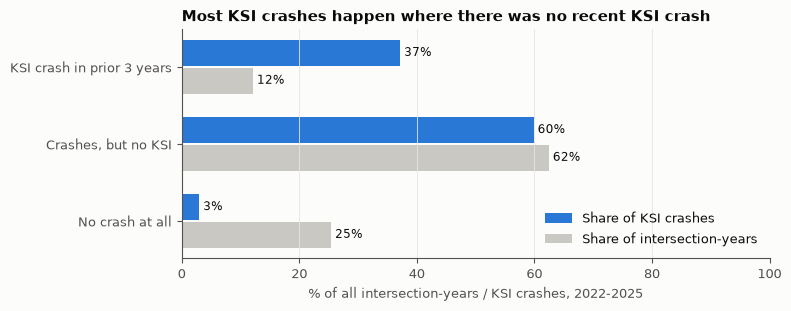

In [3]:
group = np.select([panel["ksi_lag3"] > 0, panel["crashes_lag3"] > 0],
                  ["KSI crash in prior 3 years", "Crashes, but no KSI"], "No crash at all")
by_record = (panel.assign(record=group).groupby("record")
             .agg(intersection_years=("ksi", "size"), ksi=("ksi", "sum"))
             .reindex(["KSI crash in prior 3 years", "Crashes, but no KSI", "No crash at all"]))
by_record["share of intersection-years"] = by_record["intersection_years"] / by_record["intersection_years"].sum()
by_record["share of KSI crashes"] = by_record["ksi"] / by_record["ksi"].sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(by_record))
for col, color, offset in [("share of KSI crashes", WITH_HISTORY, -0.18), ("share of intersection-years", MUTED, 0.18)]:
    ax.barh(y + offset, by_record[col] * 100, height=0.34, color=color, label=col[0].upper() + col[1:])
    for yi, v in zip(y + offset, by_record[col] * 100):
        ax.text(v, yi, f" {v:.0f}%", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, by_record.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of all intersection-years / KSI crashes, 2022-2025")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Most KSI crashes happen where there was no recent KSI crash")
fig.tight_layout()
by_record.style.format({"share of intersection-years": "{:.1%}", "share of KSI crashes": "{:.1%}"})

## 2. How well does each model rank all intersections?
Top-k capture: the share of next year's KSI crashes at the model's top 100 / 1,000 intersections, averaged over 2024 and 2025. Every intersection is a candidate, crashed or not. Every unit is an intersection, so 4-leg and 5+ leg are compared with 3-leg ones.

In [4]:
HISTORY = [f"log1p_{c}_lag3" for c in
           ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]]
# legs_3 is the reference (every unit is an intersection); roadway_missing flags a single intersection
DESIGN = [f for f in ROADWAY_FEATURES if f not in ("legs_3", "roadway_missing")]
specs = {
    "Crash history (Q1 model)": HISTORY,
    "Crash history + design": HISTORY + DESIGN,
    "Design only": DESIGN,
}
config = ValidationConfig(top_k=(100, 1000))
rows, preds = [], {}
for name, features in specs.items():
    capture, _, preds[name] = evaluate(lambda f=features: NegativeBinomialModel(f), panel, config)
    by_k = capture.groupby("k")["capture"].mean()
    deviance = preds[name].groupby("year").apply(lambda d: poisson_deviance(d.ksi, d.pred)).mean()
    rows.append({"model": name, "top 100": by_k[100], "top 1,000": by_k[1000], "deviance": deviance})
results = pd.DataFrame(rows).set_index("model")
results.style.format({"top 100": "{:.1%}", "top 1,000": "{:.1%}", "deviance": "{:.4f}"})

,top 100,"top 1,000",deviance
model,,,
Crash history (Q1 model),3.3%,18.7%,0.2572
Crash history + design,3.0%,18.4%,0.2547
Design only,1.2%,9.9%,0.2842


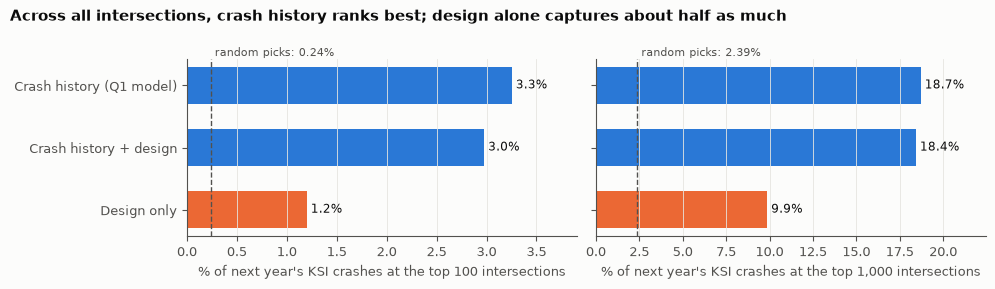

In [5]:
def plot_capture(results, ks, n_units, title):
    """Top-k capture per model, one panel per k, with the share random picks would capture."""
    fig, axes = plt.subplots(1, len(ks), figsize=(10, 0.5 * len(results) + 1.4), sharey=True)
    for ax, k in zip(axes, ks):
        values = results[k] * 100
        ax.barh(results.index, values, height=0.6,
                color=[WITH_HISTORY if n.startswith("Crash history") else WITHOUT_HISTORY for n in results.index])
        for yi, v in enumerate(values):
            ax.text(v, yi, f" {v:.1f}%", va="center", fontsize=8.5, color=INK)
        chance = 100 * int(k.split()[1].replace(",", "")) / n_units
        ax.axvline(chance, color=INK_2, linestyle="--", linewidth=1)
        ax.text(chance, 1.0, f" random picks: {chance:.2f}%", transform=ax.get_xaxis_transform(),
                fontsize=8, color=INK_2, va="bottom")
        ax.set_xlim(0, values.max() * 1.2)
        ax.set_xlabel(f"% of next year's KSI crashes at the {k} intersections")
        ax.grid(axis="y", visible=False)
    axes[0].invert_yaxis()
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=11)
    fig.tight_layout()

plot_capture(results, ["top 100", "top 1,000"], len(intersections),
             "Across all intersections, crash history ranks best; design alone captures about half as much")

## 3. The key test: intersections without a record
The same predictions, scored only on intersections that had **no KSI crash** (or **no crash at all**) in the prior 3 years. Capture is the share of those intersections' next-year KSI crashes found in the model's top 100 / 1,000 among them. Where there is no crash at all, crash history has nothing to go on, so it can do no better than random picks.

In [6]:
test = panel.loc[panel["year"].isin(config.test_years), ["site_id", "year", "ksi_lag3", "crashes_lag3"]]
SUBSETS = {"No KSI in prior 3 years": "ksi_lag3 == 0", "No crash at all in prior 3 years": "crashes_lag3 == 0"}
rows = []
for subset, condition in SUBSETS.items():
    for name, pred in preds.items():
        scored = pred.merge(test, on=["site_id", "year"]).query(condition)
        by_year = scored.groupby("year")
        row = {"subset": subset, "model": name}
        for k in (100, 1000):
            row[f"top {k:,}"] = np.mean([top_k_capture(g.ksi, g.pred, k) for _, g in by_year])
        rows.append(row)
    rows.append({"subset": subset, "model": "Random picks",
                 **{f"top {k:,}": np.mean([k / len(g) for _, g in by_year]) for k in (100, 1000)}})
    print(f"{subset}: {by_year.size().mean():,.0f} intersections and {by_year.ksi.sum().mean():,.0f} KSI crashes per test year")
record_test = pd.DataFrame(rows).set_index(["subset", "model"])
record_test.style.format("{:.1%}")

No KSI in prior 3 years: 36,944 intersections and 1,390 KSI crashes per test year
No crash at all in prior 3 years: 11,226 intersections and 85 KSI crashes per test year


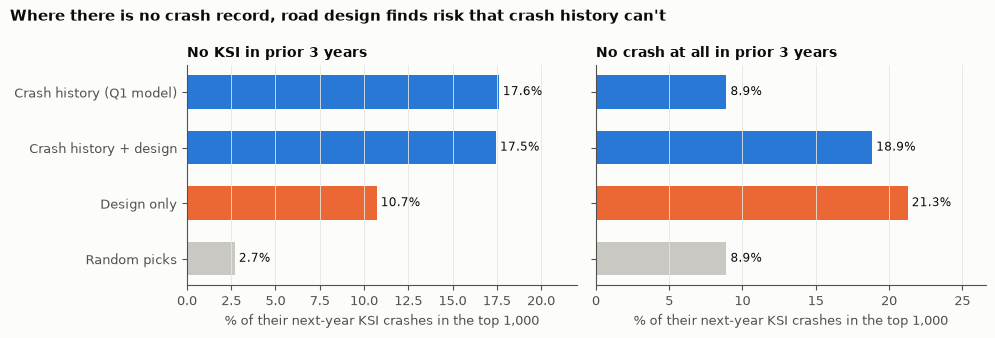

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
models = list(preds) + ["Random picks"]
colors = [WITH_HISTORY, WITH_HISTORY, WITHOUT_HISTORY, MUTED]
for ax, subset in zip(axes, SUBSETS):
    values = record_test.loc[subset, "top 1,000"].reindex(models) * 100
    ax.barh(models, values, height=0.6, color=colors)
    for yi, v in enumerate(values):
        ax.text(v, yi, f" {v:.1f}%", va="center", fontsize=8.5, color=INK)
    ax.set_xlim(0, values.max() * 1.25)
    ax.set_title(subset, fontsize=10)
    ax.set_xlabel("% of their next-year KSI crashes in the top 1,000")
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("Where there is no crash record, road design finds risk that crash history can't",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()

## 4. What makes an intersection risky by design?
Rate ratios from the design-only model fit on all years: the multiplier on expected KSI crashes, with 95% intervals clustered by intersection. No crash history is in this model, so these are total associations, including traffic that the attributes stand in for (traffic volume isn't available citywide).

,ratio,ci_low,ci_high,p_value
4-leg (vs 3-leg),2.30,2.17,2.44,0.000
5+ legs (vs 3-leg),2.75,2.27,3.35,0.000
Other intersections within 100 ft,0.74,0.69,0.79,0.000
Travel lanes (per lane),1.25,1.21,1.29,0.000
Street width (per 10 ft),1.06,1.04,1.09,0.000
Lane width (per ft),1.05,1.04,1.06,0.000
Speed limit ≤ 20,1.19,0.98,1.44,0.083
Speed limit 30–35,0.65,0.58,0.74,0.000
Speed limit 40+,0.50,0.41,0.60,0.000
One-way street,0.93,0.88,0.99,0.026


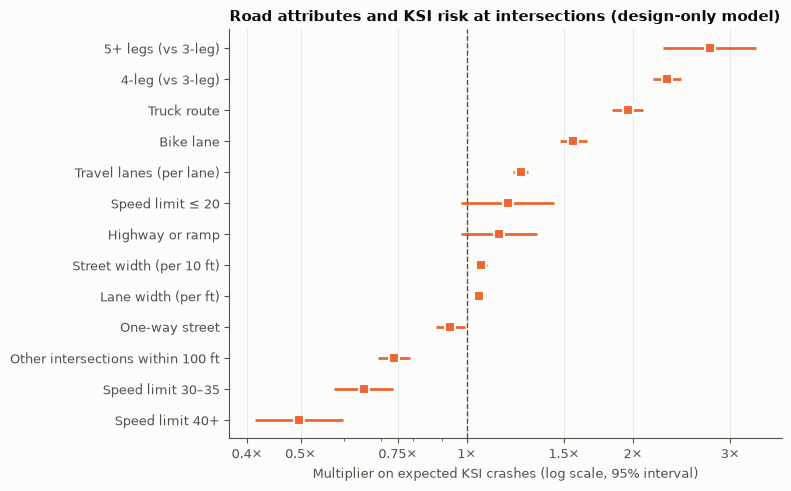

In [8]:
LABELS = {
    "legs_4": "4-leg (vs 3-leg)", "legs_5plus": "5+ legs (vs 3-leg)",
    "n_intersections": "Other intersections within 100 ft", "lanes": "Travel lanes (per lane)",
    "width_10ft": "Street width (per 10 ft)", "lane_width_ft": "Lane width (per ft)",
    "speed_20_or_less": "Speed limit ≤ 20", "speed_30_35": "Speed limit 30–35",
    "speed_40_plus": "Speed limit 40+", "one_way": "One-way street", "highway": "Highway or ramp",
    "bike_lane": "Bike lane", "truck_route": "Truck route",
}
design = NegativeBinomialModel(DESIGN).fit(panel, panel["ksi"], groups=panel["site_id"])
effects = design.coefficients().loc[list(LABELS), ["ratio", "ci_low", "ci_high", "p_value"]]

eff = effects.sort_values("ratio")
y = np.arange(len(eff))
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(y, eff.ci_low, eff.ci_high, color=WITHOUT_HISTORY, linewidth=2)
ax.scatter(eff.ratio, y, color=WITHOUT_HISTORY, marker="s", s=45, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.5, 0.75, 1, 1.5, 2, 3])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, [LABELS[f] for f in eff.index])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Multiplier on expected KSI crashes (log scale, 95% interval)")
ax.set_title("Road attributes and KSI risk at intersections (design-only model)")
fig.tight_layout()
effects.rename(index=LABELS).style.format("{:.2f}").format("{:.3f}", subset="p_value")

## 5. The risk map
Each intersection's expected KSI crashes per year from road design alone (the model above, at 2025's level). The second map shows the 1,000 highest-risk intersections by design, split by whether they had a KSI crash in 2019–2025: the orange ones are **risky by design but have no severe crash on record**, the places crash history can't flag.

Of the 1,000 highest-risk intersections by design, 334 had no KSI crash in 2019-2025


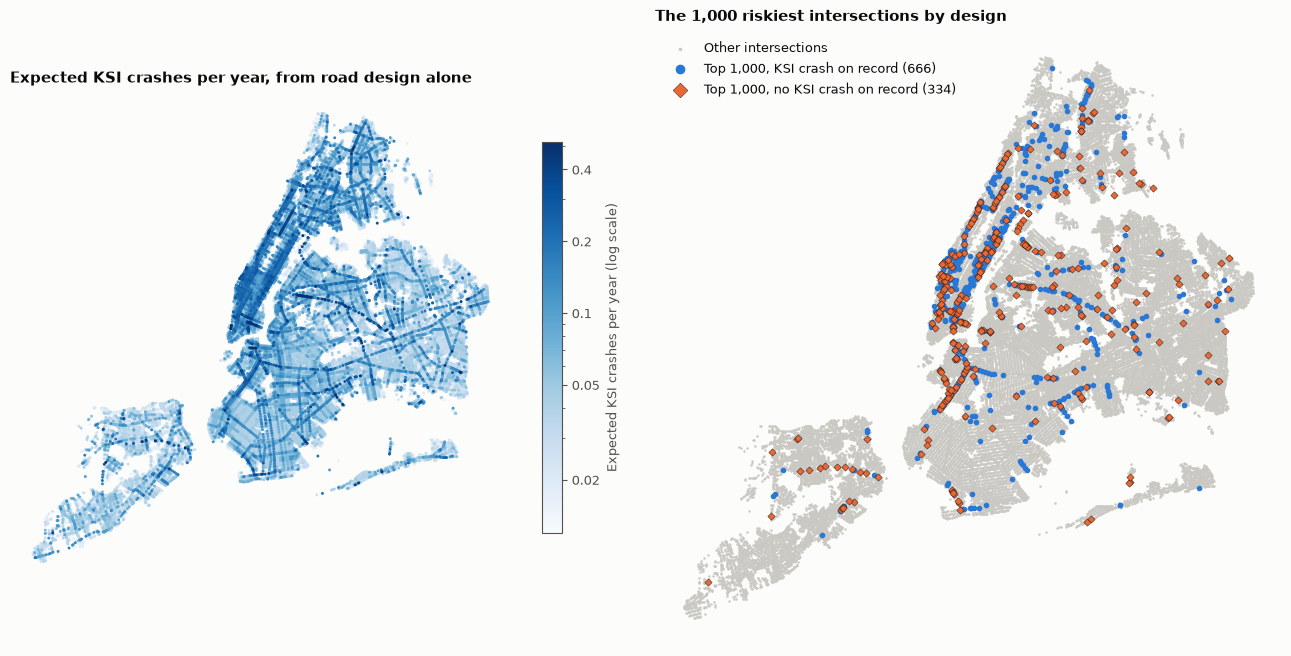

In [9]:
latest = panel[panel["year"] == panel["year"].max()].copy()
latest["predicted_ksi"] = design.predict(latest)
first = panel[panel["year"] == panel["year"].min()].set_index("site_id")
record = pd.DataFrame({
    "ksi_2019_2025": total_ksi + first["ksi_lag3"],
    "crashes_2019_2025": panel.groupby("site_id")["crashes"].sum() + first["crashes_lag3"],
})
risk = (intersections.merge(latest[["site_id", "predicted_ksi"]], on="site_id")
        .merge(record, left_on="site_id", right_index=True)
        .merge(roadway[["site_id", "legs", "lanes", "width_ft", "speed_limit", "highway", "truck_route", "bike_lane"]], on="site_id")
        .sort_values("predicted_ksi"))
top = risk.nlargest(1000, "predicted_ksi")
hidden = top[top["ksi_2019_2025"] == 0]
print(f"Of the 1,000 highest-risk intersections by design, {len(hidden)} had no KSI crash in 2019-2025")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))
ax = axes[0]
points = ax.scatter(risk.longitude, risk.latitude, c=risk.predicted_ksi, s=1.2, cmap="Blues",
                    norm=LogNorm(vmin=risk.predicted_ksi.quantile(0.05), vmax=risk.predicted_ksi.quantile(0.999)))
bar = fig.colorbar(points, ax=ax, shrink=0.6, label="Expected KSI crashes per year (log scale)")
bar.set_ticks([0.02, 0.05, 0.1, 0.2, 0.4])
bar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
bar.ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("Expected KSI crashes per year, from road design alone")
ax = axes[1]
ax.scatter(risk.longitude, risk.latitude, s=0.6, color=MUTED, label="Other intersections")
had = top[top["ksi_2019_2025"] > 0]
ax.scatter(had.longitude, had.latitude, s=9, color=WITH_HISTORY, label=f"Top 1,000, KSI crash on record ({len(had)})")
ax.scatter(hidden.longitude, hidden.latitude, s=14, color=WITHOUT_HISTORY, marker="D", edgecolor=INK, linewidth=0.3,
           label=f"Top 1,000, no KSI crash on record ({len(hidden)})")
ax.legend(loc="upper left", frameon=False, markerscale=2)
ax.set_title("The 1,000 riskiest intersections by design")
for ax in axes:
    ax.set_aspect(1 / np.cos(np.radians(40.7)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)
fig.tight_layout()

In [10]:
# the riskiest intersections by design with no KSI crash in 2019-2025;
# "highway" rows with few crashes are likely grade-separated crossings (see below)
(hidden.nlargest(25, "predicted_ksi")
 [["streets", "legs", "lanes", "width_ft", "speed_limit", "highway", "truck_route", "bike_lane",
   "crashes_2019_2025", "predicted_ksi", "latitude", "longitude"]]
 .rename(columns={"predicted_ksi": "expected KSI / year"})
 .style.format({"width_ft": "{:.0f}", "lanes": "{:.0f}", "speed_limit": "{:.0f}",
                "crashes_2019_2025": "{:.0f}", "expected KSI / year": "{:.3f}", "latitude": "{:.5f}", "longitude": "{:.5f}"})
 .hide(axis="index"))

streets,legs,lanes,width_ft,speed_limit,highway,truck_route,bike_lane,crashes_2019_2025,expected KSI / year,latitude,longitude
41 STREET & QUEENS BOULEVARD,4,8,106,25,False,True,True,21,0.687,40.74370,-73.92334
BRONX SHORE ROAD & ROBERT F KENNEDY BRIDGE,4,6,260,40,True,True,True,0,0.679,40.79968,-73.92626
JEWEL AVENUE & KISSENA BOULEVARD,4,8,100,25,False,True,True,53,0.656,40.73204,-73.81492
44 STREET & QUEENS BOULEVARD,4,8,106,25,False,True,True,41,0.644,40.74337,-73.92056
45 STREET & QUEENS BOULEVARD,4,8,104,25,False,True,True,34,0.636,40.74327,-73.91963
38 STREET & QUEENS BOULEVARD,4,8,104,25,False,True,True,50,0.636,40.74413,-73.92705
39 PLACE & QUEENS BOULEVARD,4,8,104,25,False,True,True,26,0.636,40.74392,-73.92519
47 STREET & QUEENS BOULEVARD,4,8,100,25,False,True,True,27,0.605,40.74305,-73.91775
GREENPOINT AVENUE & QUEENS BOULEVARD & ROOSEVELT AVENUE,4,8,100,25,False,True,True,23,0.592,40.74291,-73.91649
CROSS BRONX EXPRESSWAY & LAWTON AVENUE,4,10,163,50,True,True,False,0,0.542,40.81911,-73.80983


## What this shows
- **Most severe crashes happen where there was no recent severe crash.** 85% of the 41,897 intersections had no KSI crash in 2022–2025, and 63% of KSI crashes happened at an intersection with no KSI crash in the 3 years before (60% where there were minor crashes, 3% where there was no crash at all).
- **Across all intersections, crash history still ranks best.** Its top 1,000 intersections capture 18.7% of next year's KSI crashes; road design alone captures 9.9%, about half, and about 4× what random picks would. Adding design to crash history doesn't improve the list (18.4%), as in Q2.
- **Where there is no crash at all, design is the only signal, and it works.** Crash history does no better than random picks there (8.9%), while design captures 21.3%, 2.4× random. These places produce few KSI crashes (about 85 a year), so the gain is about 10 more KSI crashes a year found in the top 1,000.
- **Where there are minor crashes but no KSI, the minor crashes are the better warning.** Crash history captures 17.6% there against 10.7% for design. Most of the "no recent KSI" risk is already visible in a place's minor crashes.
- **What makes an intersection risky by design:** truck routes (about 2×), 4-way (2.3×) and 5+ way (2.8×) crossings compared with 3-way, bike lanes (1.6×, likely more cyclists) and each extra travel lane (1.25×). Roads posted 40+ mph have half the KSI, likely because few people walk or bike there.
- **The map:** 334 of the 1,000 highest-risk intersections by design had no KSI crash in 2019–2025. Many sit on wide arterials (Queens Boulevard, Merrick and Francis Lewis Boulevards) and have many minor crashes; some, such as parts of Queens Boulevard, were redesigned by DOT in recent years, which may be why their severe crashes dropped.

**Cautions**
- **Grade-separated crossings:** some top entries (Cross Bronx and Staten Island Expressway crossings, bridge approaches) have few or no crashes because the roads cross on different levels; LION records a node there. They are likely false positives and should be filtered before the list is used.
- **LION is a 2026 snapshot,** so a recent redesign is treated as if it had always been there.
- **No traffic volume citywide,** so part of the lane, width and truck-route effects is "busy road".
- **Associations, not causes,** and only two test years; the no-crash group has few KSI crashes, so its capture rates are noisy.

**Next steps:** filter grade-separated crossings; combine design with crash history into one score (the Highway Safety Manual's empirical Bayes method), which helps places with a short or noisy record; export the scores for GIS so DOT can review the list.